# H05. 기름 온도(와 다른 특징들)는 정상 시계열인가

| 항목 | 내용 |
|---|---|
| 질문 | 기름 온도는 실험 내내 일정했을까? 다른 특징들은? |
| 귀무가설 H0 | (ADF) 유온 시계열은 비정상이다 / (KPSS) 유온 시계열은 정상이다 |
| 대립가설 H1 | 두 검정을 함께 보고 정상·비정상을 판정 |
| 검정 | ADF + KPSS (원값과 1차 차분), 전체 특징 66개로 확대 |
| 출처 (EDA) | F19 시계열·이동평균, F20 ACF·PACF, T01 |
| 데이터 | TS1_mean 및 hyd_cycles.csv 전체 특징 |
| 왜 중요한가 | 정상성은 평가 방식(순서 블록), 시계열 모델(ARIMA) 사용 가능 여부, 통계 vs 딥러닝 판단의 기준 |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

유온의 원값, 50사이클 이동평균·이동표준편차, 1차 차분을 봅니다.

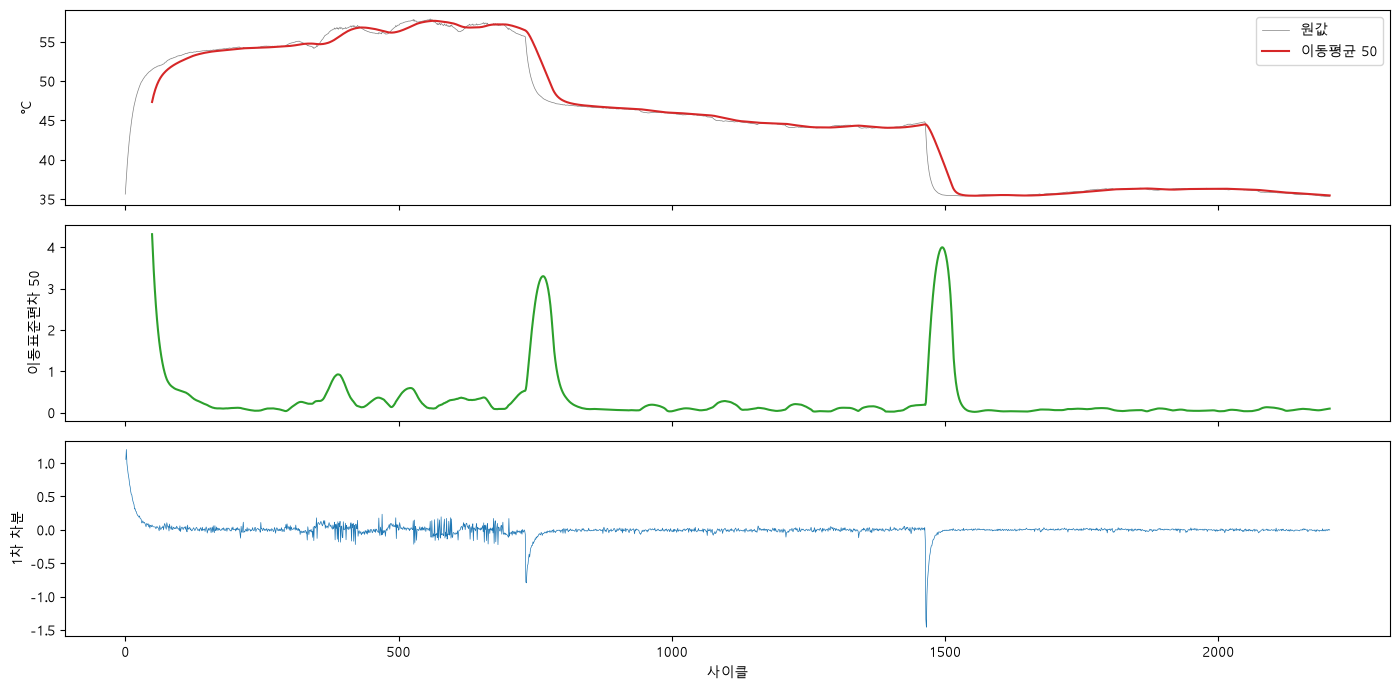

In [2]:
from statsmodels.graphics.tsaplots import plot_pacf
f = "TS1_mean"; s = cyc[f]
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
axes[0].plot(cyc["cycle"], s, lw=0.5, color="gray", label="원값"); axes[0].plot(cyc["cycle"], s.rolling(50).mean(), color="C3", label="이동평균 50")
axes[0].set_ylabel("°C"); axes[0].legend()
axes[1].plot(cyc["cycle"], s.rolling(50).std(), color="C2"); axes[1].set_ylabel("이동표준편차 50")
axes[2].plot(cyc["cycle"], s.diff(), lw=0.5); axes[2].set_ylabel("1차 차분"); axes[2].set_xlabel("사이클")
plt.tight_layout(); plt.show()

**EDA로 본 것:** 이동평균이 약 35~57 °C 사이를 크게 오르내립니다. 평균이 일정하지 않으니 비정상으로 예상됩니다. 1차 차분은 0 주변에서 움직이지만, 냉각기가 바뀌는 시점에 크게 튑니다.

## 2. 기술통계 (구간별)

In [3]:
display(s.groupby(pd.cut(cyc['cycle'], 6)).agg(['mean', 'std', 'min', 'max']).round(2))

,mean,std,min,max
cycle,,,,
"(-2.204, 367.333]",53.08,2.88,35.62,55.85
"(367.333, 734.667]",56.85,0.57,54.04,57.90
"(734.667, 1102.0]",46.51,1.19,44.88,53.40
"(1102.0, 1469.333]",44.30,0.48,39.46,44.90
"(1469.333, 1836.667]",35.78,0.44,35.38,38.90
"(1836.667, 2204.0]",36.03,0.32,35.31,36.38


## 3. 가정 확인

ADF·KPSS는 분포 가정보다 **자기상관 차수(시차)** 선택이 중요합니다. ADF는 AIC로 시차를 자동 선택하고, KPSS는 nlags='auto'를 씁니다. ACF·PACF로 자기상관 구조를 먼저 봅니다.

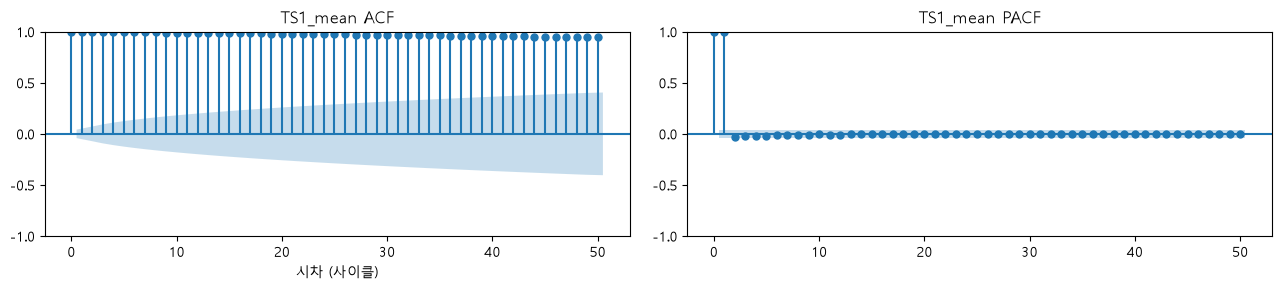

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3))
acf_plot(s, "TS1_mean ACF", ax=axes[0]); plot_pacf(s, lags=50, ax=axes[1], method="ywm", title="TS1_mean PACF")
plt.tight_layout(); plt.show()

## 4·5. 정상성 검정 (p-값) — 유온

| ADF (H0: 비정상) | KPSS (H0: 정상) | 판정 |
|---|---|---|
| 기각 | 기각 못 함 | 정상 |
| 기각 못 함 | 기각 | 비정상 |
| 기각 | 기각 | 추세·구조 변화 → 추세 제거 후 재검정 |
| 기각 못 함 | 기각 못 함 | 판단 불가 |

In [5]:
from statsmodels.tsa.stattools import adfuller, kpss
for nm, x in [("원값", s), ("1차 차분", s.diff().dropna())]:
    a = adfuller(x); k = kpss(x, regression="c", nlags="auto")
    print(f"[{nm}] ADF 통계량 = {a[0]:.2f}, p = {a[1]:.4f} (시차 {a[2]}) | KPSS 통계량 = {k[0]:.3f}, p = {k[1]:.3f}")
display(stationarity(cyc, [f]))

[원값] ADF 통계량 = -0.60, p = 0.8718 (시차 22) | KPSS 통계량 = 6.600, p = 0.010
[1차 차분] ADF 통계량 = -8.68, p = 0.0000 (시차 21) | KPSS 통계량 = 0.600, p = 0.023


,특징,계열,ADF_p,KPSS_p,판정
0,TS1_mean,원값,8.718455e-01,0.010000,비정상
1,TS1_mean,1차 차분,4.263747e-14,0.022619,추세·구조변화(둘 다 기각)


## 6. 전체 특징으로 확대 (66개)

피드백에 따라 정상성 여부를 **모든 특징**으로 확인합니다. 값 종류가 3개 미만인 특징은 뺍니다.

,특징 수,비율
판정,,
비정상,38,0.576
추세·구조변화(둘 다 기각),24,0.364
정상,4,0.061


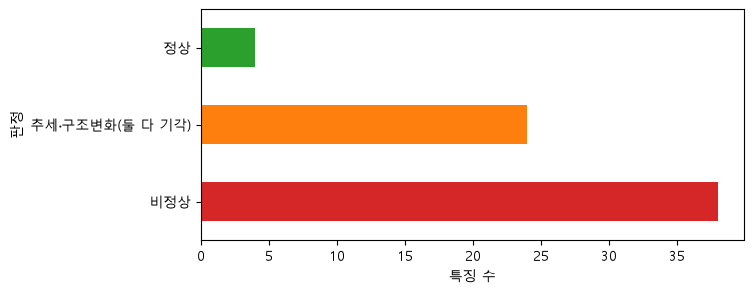

,특징,계열,ADF_p,KPSS_p,판정
2,PS1_min,원값,0.8950,0.010,비정상
3,PS1_max,원값,0.4790,0.010,비정상
9,PS3_max,원값,0.6727,0.010,비정상
10,PS4_mean,원값,0.5332,0.010,비정상
12,PS4_min,원값,0.6161,0.010,비정상
13,PS4_max,원값,0.5126,0.010,비정상
14,PS5_mean,원값,0.8990,0.010,비정상
16,PS5_min,원값,0.9055,0.010,비정상
17,PS5_max,원값,0.8933,0.010,비정상
18,PS6_mean,원값,0.9012,0.010,비정상


In [6]:
FEAT = features(cyc)
allst = stationarity(cyc, FEAT, diff=False)
cnt = allst["판정"].value_counts(); display(cnt.to_frame("특징 수").assign(비율=lambda d: (d["특징 수"] / d["특징 수"].sum()).round(3)))
fig, ax = plt.subplots(figsize=(7, 3)); cnt.plot.barh(ax=ax, color=["C3", "C1", "C2", "C7"][:len(cnt)]); ax.set_xlabel("특징 수"); plt.show()
display(allst.sort_values("판정").style.format({"ADF_p": "{:.4f}", "KPSS_p": "{:.3f}"}))

## 7. 차분 후에는?

비정상 특징을 1차 차분하면 정상이 되는지 봅니다. 정상이 되면 "추세(평균의 이동)"가 원인입니다.

In [7]:
nonst = allst.loc[allst["판정"] != "정상", "특징"].tolist()
dst = stationarity(cyc.assign(**{x: cyc[x].diff() for x in nonst}), nonst, diff=False)
print("원값이 정상이 아니던 특징", len(nonst), "개 → 1차 차분 후 판정:"); display(dst["판정"].value_counts().to_frame("특징 수"))

원값이 정상이 아니던 특징 62 개 → 1차 차분 후 판정:


,특징 수
판정,
정상,41
추세·구조변화(둘 다 기각),21


## 8. 최종 판정

In [8]:
ts = stationarity(cyc, [f]).set_index("계열")
final = pd.DataFrame([dict(가설="H05", 검정="ADF + KPSS", 유온_ADF_p=ts.loc["원값", "ADF_p"], 유온_KPSS_p=ts.loc["원값", "KPSS_p"],
    유온_판정=ts.loc["원값", "판정"], 전체_정상=int(cnt.get("정상", 0)), 전체_특징=int(cnt.sum()),
    판정="비정상 (H1 지지)" if ts.loc["원값", "판정"] == "비정상" else ts.loc["원값", "판정"])])
display(final)
save_result("H05", title="유온·전체 특징 정상성", test="ADF + KPSS", stat=f"전체 {int(cnt.sum())}개 중 정상 {int(cnt.get('정상', 0))}개",
            p=ts.loc["원값", "ADF_p"], effect="-", verdict=final.판정[0], counts=cnt.to_dict())

,가설,검정,유온_ADF_p,유온_KPSS_p,유온_판정,전체_정상,전체_특징,판정
0,H05,ADF + KPSS,0.871845,0.01,비정상,4,66,비정상 (H1 지지)


저장: results/H05.json


## 9. 해석과 결정

- 유온은 **비정상**입니다(ADF p ≈ 0.87, KPSS p ≤ 0.01). 전체 특징 66개 중 정상은 4개(약 6%)뿐입니다. 나머지는 비정상이거나 평균이 몇 번 갑자기 바뀌는 형태입니다.
- 1차 차분하면 대부분 정상이 됩니다. 원인은 **평균이 시간에 따라 이동하는 것(추세·구조 변화)**입니다.
- **결정:**
  1. 정상성을 가정하는 ARIMA 같은 고전 시계열 모델은 RUL에 쓰지 않고, **P-F 간격 방식을 유지**합니다.
  2. 평가는 **순서 블록 분할**로 합니다.
  3. 모델은 처음 보는 조건에서 버티는 것을 골라야 합니다. 통계 vs 딥러닝 판단은 99번 노트북에서 합니다.